# 2. One message-passing step, by hand

**What you will learn:** exactly what happens to the numbers in one layer.
We take a five-atom molecule, make up a tiny two-dimensional feature vector
for each atom, and watch those numbers travel from atom to atom. No
abstraction, no library call you cannot see inside.

The molecule is **propanoic acid**, `CCC(=O)O`, five heavy atoms. Small enough
that you can check every arithmetic step with a pen.

Message passing is three verbs, repeated:

1. **Message** — every atom prepares something to send to its neighbours.
2. **Aggregate** — every atom combines what arrived, with an operation that
   does not care about ordering (sum, mean, max): neighbours have no
   canonical order, so the aggregation must not invent one.
3. **Update** — the atom combines what arrived with what it already had.

Everything in notebooks 3 and 4 is a different choice of those three verbs.

CCC(=O)O -> ['C0', 'C1', 'C2', 'O3', 'O4']


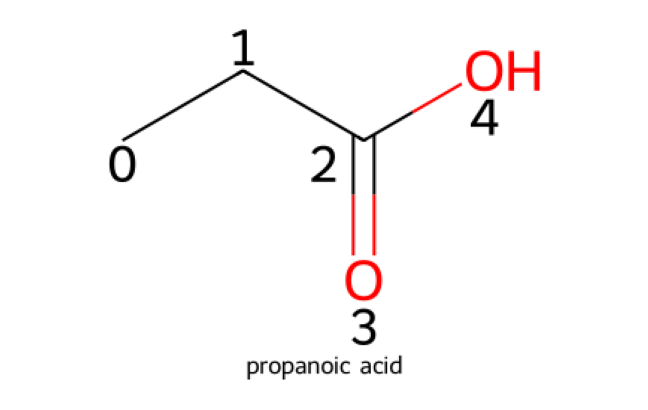

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from mgnn import features as F
from mgnn.layers import GCNLayer, message_passing_step_numpy
from mgnn.viz import draw_molecule_with_indices, show

np.set_printoptions(precision=3, suppress=True, linewidth=120)
plt.rcParams["figure.dpi"] = 110

smiles = "CCC(=O)O"
graph = F.smiles_to_graph(smiles)
labels = graph.atom_symbols()
labels = [f"{s}{i}" for i, s in enumerate(labels)]
print(smiles, "->", labels)
show(draw_molecule_with_indices(smiles, size=(420, 260), legend="propanoic acid"))
plt.show()

## 2.1 A toy feature vector

The real featuriser gives each atom 34 numbers (notebook 01). For hand-tracing
that is 34 columns of noise, so here each atom gets just two features:

* **feature 0** — "is this a carbon?" (1 or 0)
* **feature 1** — "is this an oxygen?" (1 or 0)

Nothing in the mathematics changes; only the width.

In [2]:
A = F.adjacency_matrix(graph)
X = np.array([
    [1.0, 0.0],   # C0  methyl
    [1.0, 0.0],   # C1  methylene
    [1.0, 0.0],   # C2  carboxyl carbon
    [0.0, 1.0],   # O3  carbonyl oxygen
    [0.0, 1.0],   # O4  hydroxyl oxygen
])
display(pd.DataFrame(X, index=labels, columns=["is_C", "is_O"]))
print("adjacency:")
display(pd.DataFrame(A.astype(int), index=labels, columns=labels))

,is_C,is_O
C0,1.0,0.0
C1,1.0,0.0
C2,1.0,0.0
O3,0.0,1.0
O4,0.0,1.0


adjacency:


,C0,C1,C2,O3,O4
C0,0,1,0,0,0
C1,1,0,1,0,0
C2,0,1,0,1,1
O3,0,0,1,0,0
O4,0,0,1,0,0


Read off the neighbourhoods and keep them in mind; every number below is
traceable to this list.

In [3]:
for i, lab in enumerate(labels):
    nbrs = [labels[j] for j in range(len(labels)) if A[i, j]]
    print(f"  {lab}: neighbours {nbrs}")

  C0: neighbours ['C1']
  C1: neighbours ['C0', 'C2']
  C2: neighbours ['C1', 'O3', 'O4']
  O3: neighbours ['C2']
  O4: neighbours ['C2']


## 2.2 Step 1 — the message

In a graph convolution the message an atom sends is just its own feature
vector, transformed by a weight matrix $W$ **shared by every atom in every
molecule**. That sharing is the point: a model trained on 5,000 molecules has
seen that one matrix used millions of times, which is why GNNs are far more
data-efficient than a per-atom parameterisation would be.

Pick $W$ by hand so the output stays readable. Two output channels:

* channel 0 = "carbon-ness", mostly passing `is_C` through
* channel 1 = "oxygen-ness", mostly passing `is_O` through

In [4]:
W = np.array([
    [1.0, 0.0],
    [0.0, 2.0],
])
XW = X @ W
display(pd.DataFrame(XW, index=labels, columns=["chan0 (C-ness)", "chan1 (O-ness)"]))
print("Each oxygen now sends 2.0 down channel 1; each carbon sends 1.0 down channel 0.")

,chan0 (C-ness),chan1 (O-ness)
C0,1.0,0.0
C1,1.0,0.0
C2,1.0,0.0
O3,0.0,2.0
O4,0.0,2.0


Each oxygen now sends 2.0 down channel 1; each carbon sends 1.0 down channel 0.


## 2.3 Step 2 — aggregate, and the first real design decision

Atom $i$ sums what its neighbours sent:

$$ m_i = \sum_{j \in N(i)} (W x_j)$$

In matrix form that is a single multiplication, $A \, XW$. One line of code
**is** the aggregation step over the whole molecule at once.

In [5]:
aggregated_raw = A @ XW
display(pd.DataFrame(aggregated_raw, index=labels,
                     columns=["chan0 received", "chan1 received"]))

,chan0 received,chan1 received
C0,1.0,0.0
C1,2.0,0.0
C2,1.0,4.0
O3,1.0,0.0
O4,1.0,0.0


Trace one row to be sure. Atom **C2** (the carboxyl carbon) is bonded to C1,
O3 and O4, so it receives

$$ m_{C2} = (1,0)_{C1} + (0,2)_{O3} + (0,2)_{O4} = (1, 4) $$

and the table says `C2 -> [1, 4]`. The methyl **C0** touches only C1 and
receives `[1, 0]`. A single layer gives every atom a summary of its immediate
chemical environment — C2 "knows" it sits next to two oxygens, which is the
beginning of knowing it is a carboxylic acid.

Notice what is broken, though: **the atom's own identity is gone.** Row C0
describes C1, not C0. Two layers of this and an atom is a description of its
neighbourhood with itself deleted.

In [6]:
print("own features of C0 :", X[0], "   what C0 received:", aggregated_raw[0])
print("own features of O3 :", X[3], "   what O3 received:", aggregated_raw[3])
print("\nThe received vectors say nothing about the atom itself. Hence self-loops.")

own features of C0 : [1. 0.]    what C0 received: [1. 0.]
own features of O3 : [0. 1.]    what O3 received: [1. 0.]

The received vectors say nothing about the atom itself. Hence self-loops.


## 2.4 Self-loops: let the atom hear itself

The fix is to add an edge from every atom to itself, $\tilde{A} = A + I$, so
each atom's own message arrives alongside its neighbours'.

In [7]:
A_tilde = A + np.eye(len(labels))
display(pd.DataFrame(A_tilde.astype(int), index=labels, columns=labels))
aggregated_self = A_tilde @ XW
display(pd.DataFrame(aggregated_self, index=labels,
                     columns=["chan0", "chan1"]).style.format("{:.2f}"))
print("C2 now reports [2, 4]: its own 1.0 of carbon-ness plus the 1.0 from C1, "
      "plus 2.0 from each oxygen.")

,C0,C1,C2,O3,O4
C0,1,1,0,0,0
C1,1,1,1,0,0
C2,0,1,1,1,1
O3,0,0,1,1,0
O4,0,0,1,0,1


,chan0,chan1
C0,2.00,0.00
C1,3.00,0.00
C2,2.00,4.00
O3,1.00,2.00
O4,1.00,2.00


C2 now reports [2, 4]: its own 1.0 of carbon-ness plus the 1.0 from C1, plus 2.0 from each oxygen.


## 2.5 Degree normalisation: stop the hubs from shouting

A quaternary carbon receives four messages, a terminal methyl one. With a bare
sum, activations scale with degree and the first layer already produces values
of wildly different magnitude for chemically unremarkable reasons. GCN divides
that out symmetrically:

$$ \hat{A} = \tilde{D}^{-1/2}\,(A + I)\,\tilde{D}^{-1/2}, \qquad
   \hat{A}_{ij} = \frac{1}{\sqrt{d_i}\sqrt{d_j}} $$

where $d_i$ is atom $i$'s degree *including* its self-loop. A message from a
high-degree neighbour is discounted twice: once because the receiver is busy,
once because the sender is.

In [8]:
trace = message_passing_step_numpy(X, A, W)

print("degrees including self-loop:", dict(zip(labels, trace["degree"].astype(int))))
print("\nnormalised adjacency A_hat:")
display(pd.DataFrame(trace["A_hat"], index=labels, columns=labels).style.format("{:.3f}"))
print("rows of A_hat sum to:", np.round(trace['A_hat'].sum(axis=1), 3),
      "  (not 1 -- symmetric normalisation is not row-stochastic)")

degrees including self-loop: {'C0': np.int64(2), 'C1': np.int64(3), 'C2': np.int64(4), 'O3': np.int64(2), 'O4': np.int64(2)}

normalised adjacency A_hat:


,C0,C1,C2,O3,O4
C0,0.500,0.408,0.000,0.000,0.000
C1,0.408,0.333,0.289,0.000,0.000
C2,0.000,0.289,0.250,0.354,0.354
O3,0.000,0.000,0.354,0.500,0.000
O4,0.000,0.000,0.354,0.000,0.500


rows of A_hat sum to: [0.908 1.03  1.246 0.854 0.854]   (not 1 -- symmetric normalisation is not row-stochastic)


## 2.6 The whole step, intermediate by intermediate

Now run it end to end and print every stage. This is the complete contents of
one graph convolution layer.

In [9]:
for name in ["XW", "aggregated", "out"]:
    print(f"--- {name} ---")
    display(pd.DataFrame(trace[name], index=labels,
                         columns=["chan0", "chan1"]).style.format("{:.3f}"))

--- XW ---


,chan0,chan1
C0,1.000,0.000
C1,1.000,0.000
C2,1.000,0.000
O3,0.000,2.000
O4,0.000,2.000


--- aggregated ---


,chan0,chan1
C0,0.908,0.000
C1,1.030,0.000
C2,0.539,1.414
O3,0.354,1.000
O4,0.354,1.000


--- out ---


,chan0,chan1
C0,0.908,0.000
C1,1.030,0.000
C2,0.539,1.414
O3,0.354,1.000
O4,0.354,1.000


## 2.7 Watching one feature travel

Here is the clearest demonstration that information *moves*. Give a single
atom a signal of 1 and the rest 0, then apply the same propagation repeatedly
with the weight matrix set to the identity. Each application pushes the signal
one bond further.

Start the pulse on **O3**, the carbonyl oxygen, and watch it spread.

In [10]:
pulse = np.zeros((len(labels), 1))
pulse[3, 0] = 1.0
A_hat = trace["A_hat"]

history = [pulse.copy()]
h = pulse.copy()
for _ in range(4):
    h = A_hat @ h          # identity weights: pure propagation, no transformation
    history.append(h.copy())

frame = pd.DataFrame(np.hstack(history), index=labels,
                     columns=[f"after {k} layers" for k in range(len(history))])
display(frame.style.format("{:.3f}").background_gradient(cmap="Blues", axis=None))

,after 0 layers,after 1 layers,after 2 layers,after 3 layers,after 4 layers
C0,0.000,0.000,0.000,0.042,0.066
C1,0.000,0.000,0.102,0.111,0.133
C2,0.000,0.354,0.265,0.273,0.255
O3,1.000,0.500,0.375,0.281,0.237
O4,0.000,0.000,0.125,0.156,0.174


Read the table row by row:

* **after 0 layers** only O3 is lit.
* **after 1 layer** O3 and its one neighbour C2 are lit: the signal crossed one bond.
* **after 2 layers** C1 and O4 join — two bonds from O3.
* **after 3 layers** C0, the far end of the chain, finally hears about the
  carbonyl oxygen.

**This is the single most important fact about depth in a GNN.** An atom's
representation after $k$ layers depends on exactly the atoms within $k$ bonds
of it — its $k$-hop neighbourhood, its *receptive field*. Want the model to
relate two groups five bonds apart? You need five layers, or a shortcut
(notebook 09 shows the 1995 answer: let a single layer reach every atom at
once).

Look at the last column, though: the signal is spreading out and flattening.
Push this further and every atom converges to the same value. That is
**oversmoothing**, and it is why you cannot simply stack 20 layers to get a
large receptive field. Notebook 06 measures it.

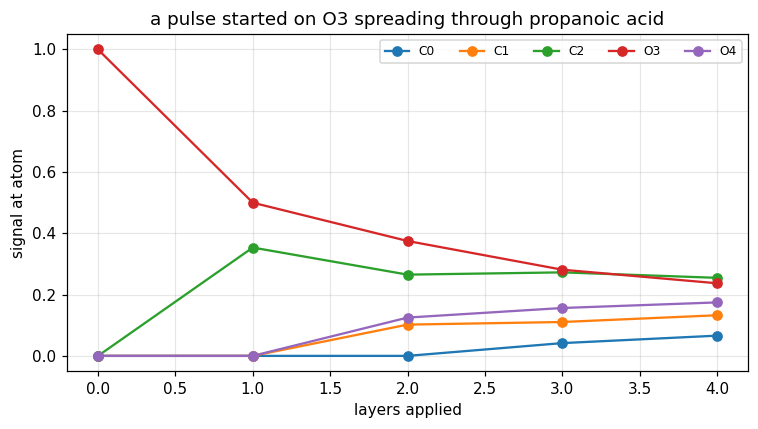

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
for i, lab in enumerate(labels):
    ax.plot(range(len(history)), [h[i, 0] for h in history], marker="o", label=lab)
ax.set_xlabel("layers applied")
ax.set_ylabel("signal at atom")
ax.set_title("a pulse started on O3 spreading through propanoic acid")
ax.legend(ncol=5, fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 2.8 The same thing, in the library

Everything above was NumPy written out longhand. `mgnn.layers.GCNLayer` does
precisely this with learned weights. To prove the code matches the arithmetic,
load our hand-picked $W$ into the layer, switch the bias off, and compare.

In [12]:
layer = GCNLayer(2, 2, bias=False)
with torch.no_grad():
    # nn.Linear stores weights transposed relative to the maths above
    layer.lin.weight.copy_(torch.tensor(W.T, dtype=torch.float))

out_layer = layer(torch.tensor(X, dtype=torch.float), graph.edge_index).detach().numpy()
print("hand-computed:\n", trace["out"])
print("\nGCNLayer:\n", out_layer)
print("\nidentical to 1e-6:", np.allclose(trace["out"], out_layer, atol=1e-6))

hand-computed:
 [[0.908 0.   ]
 [1.03  0.   ]
 [0.539 1.414]
 [0.354 1.   ]
 [0.354 1.   ]]

GCNLayer:
 [[0.908 0.   ]
 [1.03  0.   ]
 [0.539 1.414]
 [0.354 1.   ]
 [0.354 1.   ]]

identical to 1e-6: True


## What to take away

* One layer = message, aggregate, update. The aggregation must be
  order-independent, because neighbours have no canonical order.
* Self-loops exist so an atom does not forget itself.
* Degree normalisation exists so high-degree atoms do not dominate.
* After $k$ layers an atom sees exactly $k$ bonds out, and repeated averaging
  flattens the differences between atoms.

**Next:** notebook 03 looks hard at the normalised adjacency — the alternatives,
what each one does to a real molecule, and why the symmetric form won.